# 03 · Transcripción con Basic Pitch: stems vs mezcla

**Fase 0.** ¿Separar antes de transcribir mejora el resultado? Es la primera evidencia para la pregunta de ablation de la Fase 3, ahora con grabaciones reales.

- **Rock real (MUSDB18):** no hay MIDI, pero sí el stem verdadero del bajo. La transcripción de Basic Pitch sobre el bajo verdadero sirve de referencia, y se compara con transcribir el stem de Demucs o la mezcla.
- **Take Five (TRIOS):** saxo, piano y batería reales con el MIDI alineado: F1 contra la partitura de verdad, incluido el piano (la duda abierta del notebook anterior) y la batería.

Requiere haber corrido `02_separacion_demucs.ipynb` (usa sus stems de MUSDB).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")  # repo root: src.*

import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

REAL = Path("../data/real")  # npm run local:real-audio
OUTPUTS = Path("../outputs")
SR = 22050

import pretty_midi

from src.contract import instruments as catalog
from src.evaluation import datasets, metrics
from src.pipeline import audio as audio_io, drums, separation, symbolic, transcription
from src.pipeline.notes import Note, from_pretty_midi

MUSDB = REAL / "musdb7" / "test"
SEP_DIR = OUTPUTS / "separation" / separation.MODEL / "musdb"
basic_pitch = transcription.basic_pitch  # modelo cacheado, igual que el pipeline

def row(label, reference, estimate):
    r = metrics.note_f1(reference, estimate)
    print(f"{label:46s} P={r['precision']:.2f}  R={r['recall']:.2f}  F1={r['f1']:.2f}  ({len(estimate)} notas)")
    return r

## 1. Bajo en rock real

Para cada canción de prueba de MUSDB: Basic Pitch sobre el **bajo verdadero** (referencia), sobre el **stem de Demucs** y sobre la **mezcla**, siempre acotado al rango del bajo y con la limpieza del pipeline. Ojo: la referencia es la salida de un modelo, no una partitura; mide cuánto se pierde por separar o por no separar.

Predicting MIDI for ../data/real/musdb7/test/AM Contra - Heart Peripheral/bass.wav...


Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/AM Contra - Heart Peripheral/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/AM Contra - Heart Peripheral/mixture.wav...
Predicting MIDI for ../data/real/musdb7/test/Al James - Schoolboy Facination/bass.wav...


Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Al James - Schoolboy Facination/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Al James - Schoolboy Facination/mixture.wav...


Predicting MIDI for ../data/real/musdb7/test/Angels In Amplifiers - I'm Alright/bass.wav...
Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Angels In Amplifiers - I'm Alright/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Angels In Amplifiers - I'm Alright/mixture.wav...


Predicting MIDI for ../data/real/musdb7/test/Arise - Run Run Run/bass.wav...
Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Arise - Run Run Run/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Arise - Run Run Run/mixture.wav...


...

Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Timboz - Pony/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Timboz - Pony/mixture.wav...
Predicting MIDI for ../data/real/musdb7/test/Tom McKenzie - Directions/bass.wav...


Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Tom McKenzie - Directions/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Tom McKenzie - Directions/mixture.wav...
Predicting MIDI for ../data/real/musdb7/test/Triviul feat. The Fiend - Widow/bass.wav...


Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Triviul feat. The Fiend - Widow/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Triviul feat. The Fiend - Widow/mixture.wav...
Predicting MIDI for ../data/real/musdb7/test/We Fell From The Sky - Not You/bass.wav...


Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/We Fell From The Sky - Not You/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/We Fell From The Sky - Not You/mixture.wav...
Predicting MIDI for ../data/real/musdb7/test/Zeno - Signs/bass.wav...


Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Zeno - Signs/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Zeno - Signs/mixture.wav...
50 canciones con bajo
F1 vs bajo verdadero · stem Demucs: mediana=0.42  ·  mezcla: mediana=0.16
El stem de Demucs gana en 92% de las canciones


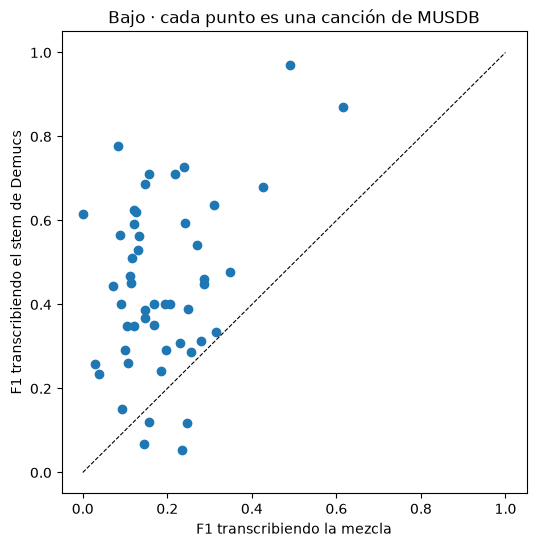

In [2]:
bass = catalog.get("bass")
def bass_notes(path):
    return symbolic.prepare(basic_pitch(path, bass.low - 12, bass.high + 12), bass)

results = []
for folder in sorted(MUSDB.iterdir()):
    true_stem = folder / "bass.wav"
    y, _ = librosa.load(true_stem, sr=SR, mono=True)
    if np.abs(y).max() < 1e-3 or not (SEP_DIR / folder.name / "bass.wav").exists():
        continue  # sin bajo o sin separar
    reference = bass_notes(true_stem)
    if len(reference) < 3:
        continue
    results.append({
        "song": folder.name,
        "ref": len(reference),
        "demucs": metrics.note_f1(reference, bass_notes(SEP_DIR / folder.name / "bass.wav"))["f1"],
        "mix": metrics.note_f1(reference, bass_notes(folder / "mixture.wav"))["f1"],
    })

demucs_f1 = np.array([r["demucs"] for r in results]); mix_f1 = np.array([r["mix"] for r in results])
print(f"{len(results)} canciones con bajo")
print(f"F1 vs bajo verdadero · stem Demucs: mediana={np.median(demucs_f1):.2f}  ·  mezcla: mediana={np.median(mix_f1):.2f}")
print(f"El stem de Demucs gana en {np.mean(demucs_f1 > mix_f1):.0%} de las canciones")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(mix_f1, demucs_f1)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("F1 transcribiendo la mezcla"); ax.set_ylabel("F1 transcribiendo el stem de Demucs")
ax.set_title("Bajo · cada punto es una canción de MUSDB")
plt.show()

Predicting MIDI for ../data/real/musdb7/test/Louis Cressy Band - Good Time/bass.wav...
Predicting MIDI for ../outputs/separation/htdemucs_6s/musdb/Louis Cressy Band - Good Time/bass.wav...
Predicting MIDI for ../data/real/musdb7/test/Louis Cressy Band - Good Time/mixture.wav...


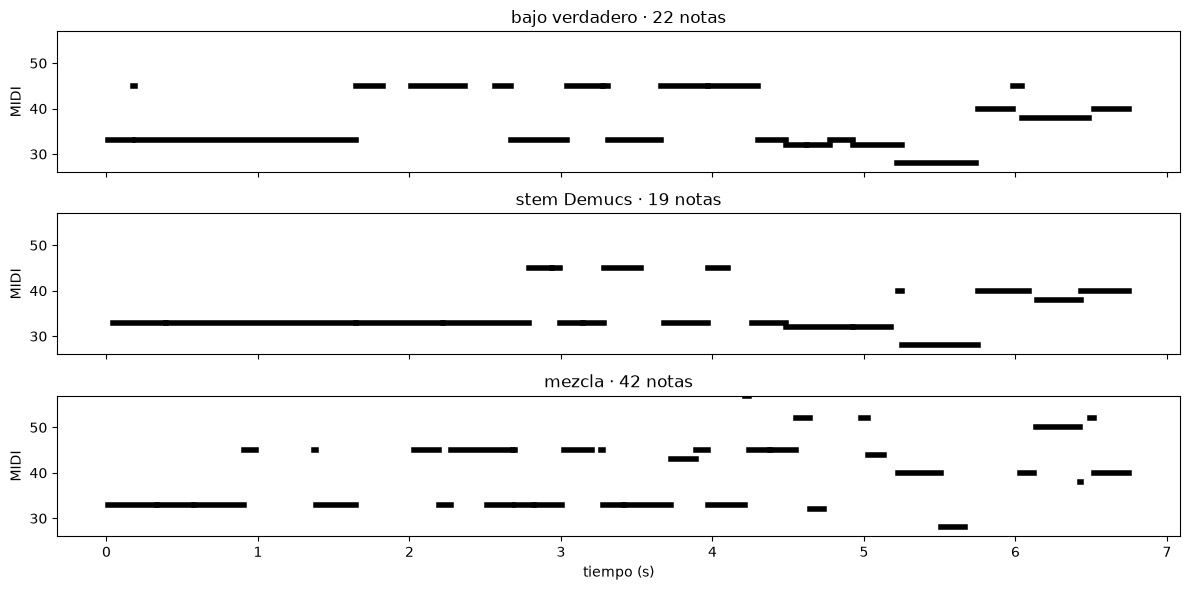

In [3]:
song = "Louis Cressy Band - Good Time"
FS, T = 50, 7
rolls = {
    "bajo verdadero": bass_notes(MUSDB / song / "bass.wav"),
    "stem Demucs": bass_notes(SEP_DIR / song / "bass.wav"),
    "mezcla": bass_notes(MUSDB / song / "mixture.wav"),
}
fig, axes = plt.subplots(len(rolls), 1, figsize=(12, 6), sharex=True)
for ax, (name, notes) in zip(axes, rolls.items()):
    for n in notes:
        ax.plot([n.start, n.end], [n.pitch, n.pitch], lw=4, color="black")
    ax.set_ylim(bass.low - 2, bass.high - 10); ax.set_title(f"{name} · {len(notes)} notas"); ax.set_ylabel("MIDI")
axes[-1].set_xlabel("tiempo (s)")
plt.tight_layout(); plt.show()

## 2. Take Five: piano, saxo y batería contra la partitura

TRIOS trae cada instrumento grabado por separado. Primero se transcribe cada pista **aislada** contra su MIDI: es el techo de Basic Pitch y, de paso, mide qué tan bien alineado está el MIDI. Después, el stem de Demucs y la mezcla.

In [4]:
track = datasets.trios_track(REAL / "trios" / "take_five")
print({k: len(v) for k, v in track.notes.items()})

out = OUTPUTS / "separation" / separation.MODEL / "trios" / "take_five"
if not (out / "piano.wav").exists():
    mix, sr = audio_io.load(track.mix)
    separation.separate(mix, sr, out)
take5 = {p.stem: p for p in out.glob("*.wav")}

for instrument, stem in (("piano", "piano"), ("alto_sax", "other")):
    inst = catalog.get(instrument)
    truth = track.notes[instrument]
    lo, hi = inst.low - 12, inst.high + 12
    print(f"\n— {inst.name} —")
    row("pista aislada real (techo)", truth, symbolic.prepare(basic_pitch(track.stems[instrument][0], lo, hi), inst))
    row(f"stem Demucs '{stem}'", truth, symbolic.prepare(basic_pitch(take5[stem], lo, hi), inst))
    row("mezcla", truth, symbolic.prepare(basic_pitch(track.mix, lo, hi), inst))

{'drums': 279, 'piano': 217, 'alto_sax': 105}

— Piano —
Predicting MIDI for ../data/real/trios/take_five/piano.wav...


pista aislada real (techo)                     P=0.58  R=0.98  F1=0.73  (366 notas)
Predicting MIDI for ../outputs/separation/htdemucs_6s/trios/take_five/piano.wav...


stem Demucs 'piano'                            P=0.60  R=0.71  F1=0.65  (257 notas)
Predicting MIDI for ../data/real/trios/take_five/mix.wav...


mezcla                                         P=0.49  R=0.91  F1=0.63  (408 notas)

— Saxo alto en Mi♭ —
Predicting MIDI for ../data/real/trios/take_five/saxophone.wav...


pista aislada real (techo)                     P=0.78  R=0.87  F1=0.82  (117 notas)
Predicting MIDI for ../outputs/separation/htdemucs_6s/trios/take_five/other.wav...


stem Demucs 'other'                            P=0.64  R=0.70  F1=0.67  (115 notas)
Predicting MIDI for ../data/real/trios/take_five/mix.wav...


mezcla                                         P=0.38  R=0.77  F1=0.51  (211 notas)


La batería se evalúa sin importar la pieza (¿encontró el golpe?) y por pieza. El detector DSP conoce bombo, caja, hi-hat y crash; *Take Five* usa **ride**, así que hi-hat y crash se cuentan como ride.

In [5]:
def as_hits(notes, ride_alias=True):
    alias = {42: 51, 49: 51} if ride_alias else {}
    return [Note(alias.get(n.pitch, n.pitch), n.start, n.end, n.velocity) for n in notes]

truth = track.notes["drums"]
for label, path in (("stem Demucs 'drums'", take5["drums"]), ("mezcla", track.mix)):
    est = as_hits(drums.transcribe(path))
    onsets_ref = sorted({round(n.start, 2) for n in truth})
    onsets_est = sorted({round(n.start, 2) for n in est})
    agnostic = metrics.note_f1([Note(60, t, t + 0.1) for t in onsets_ref],
                               [Note(60, t, t + 0.1) for t in onsets_est])
    print(f"\n{label}: golpes (sin importar pieza) F1={agnostic['f1']:.2f}")
    for name, pitch in (("bombo", 36), ("caja", 38), ("ride", 51)):
        row(f"  {name}", [n for n in truth if n.pitch == pitch], [n for n in est if n.pitch == pitch])


stem Demucs 'drums': golpes (sin importar pieza) F1=0.86
  bombo                                        P=0.68  R=0.84  F1=0.75  (31 notas)
  caja                                         P=0.71  R=0.99  F1=0.83  (143 notas)
  ride                                         P=0.56  R=0.38  F1=0.45  (104 notas)

mezcla: golpes (sin importar pieza) F1=0.82
  bombo                                        P=0.94  R=0.60  F1=0.73  (16 notas)
  caja                                         P=0.41  R=0.86  F1=0.56  (215 notas)
  ride                                         P=0.65  R=0.10  F1=0.17  (23 notas)


## Hallazgos

Ejecutado el 25 oct 2026 con grabaciones reales.

**1. Bajo en rock (50 extractos de MUSDB18).** La referencia es Basic Pitch sobre el bajo **verdadero**, que no es una partitura (por eso los F1 absolutos son bajos), pero sirve para comparar:

| Fuente               | F1 mediano vs referencia |
| -------------------- | ------------------------ |
| Stem de Demucs       | **0,42**                 |
| Mezcla               | 0,16                     |

El stem de Demucs gana en el **92 %** de las canciones. En el piano-roll se ve por qué: sobre la mezcla aparecen notas de otros instrumentos dentro del rango del bajo, y octavas de más. Al stem de Demucs se le escapan algunas notas cortas, pero lo que transcribe es bajo. **Para el bajo, separar es claramente mejor.**

**2. *Take Five* (TRIOS), contra la partitura real:**

| Instrumento | Pista aislada (techo) | Stem de Demucs | Mezcla |
| ----------- | --------------------- | -------------- | ------ |
| Saxo alto   | 0,82                  | 0,67 (`other`) | 0,51   |
| Piano       | 0,73                  | 0,65 (`piano`) | 0,63   |

- **Saxo:** separar sube el F1 de 0,51 a 0,67. Demucs no tiene stem de saxo, pero lo deja en `other`.
- **Piano real:** el stem `piano` de Demucs **sí funciona** con un piano de verdad (0,65, cerca del techo de 0,73). El 0,27 de la demo sintética era un artefacto de sus acordes de 3 armónicos. Incluso aislado, la precisión del piano es baja (0,58: 366 notas para 217 reales), por armónicos y por el pedal.

**3. Batería (*Take Five*), detector DSP:**

| Fuente         | Golpes (sin pieza) | Bombo | Caja | Ride |
| -------------- | ------------------ | ----- | ---- | ---- |
| Stem de Demucs | 0,86               | 0,75  | 0,83 | 0,45 |
| Mezcla         | 0,82               | 0,73  | 0,56 | 0,17 |

Sobre batería real separada, el detector funciona mucho mejor que en la demo (0,86 contra ≈ 0,5 en encontrar los golpes). Separar ayuda sobre todo a la caja y a los platillos. El ride sale flojo porque el detector solo conoce hi-hat y crash: aquí se contaron como ride.

**4. Bug encontrado y corregido.** Si se le pide a Basic Pitch un rango que baja de La0 (MIDI 21), devuelve **cero notas** sin avisar. El pipeline lo evitaba porque recortaba el rango antes de llamar a Basic Pitch, pero cualquier otro uso fallaba en silencio. Ahora `transcription.basic_pitch()` recorta siempre al rango del modelo (con test).